# EEG motor-imagery analysis: public BCI 2b and H100

**Kaggle edition.** Results are computed only when you run the notebook. The public and H100 evaluations use different splits and are not direct accuracy comparisons. Keep the input provenance explicit in your report.
Statistical tests are exploratory, especially after inspecting multiple models. A per-person binomial p-value assumes independent trials; EEG trials may be correlated.

The additional H100 section includes leave-one-participant-out evaluation, signal-window diagnostics, baseline-free lateralisation, a pooled confusion matrix, and a CSV header check for channel ablation. All scores are calculated from the supplied data when run; no target accuracy is imposed.


In [32]:
# Kaggle: enable Internet in Notebook settings for MOABB's public dataset download.
import os, sys, subprocess, importlib.util
required = {'moabb':'moabb', 'mne':'mne', 'pyriemann':'pyriemann', 'statsmodels':'statsmodels', 'torch':'torch'}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing:', missing)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)


In [33]:
# ---- CONFIG: edit this cell ----
SMOKE_TEST = os.environ.get('EEG_SMOKE', '0') == '1'   # leave False for real data. True = simulated data for code testing ONLY.
FAST_MODE = SMOKE_TEST                                   # set True to cut epochs/seeds for a quick trial run (results less reliable)

H100_DIR   = '/kaggle/input' if os.path.isdir('/kaggle/input') else 'upload'
H100_GLOB  = '**/filtered_eeg_*.csv'  # matches eeg_h100_filtered/h100_filtered/filtered_eeg_01.csv
CSV_SEP    = ','
COL_EVENT  = 'Event'
CH3        = ['F-C3', 'F-CZ', 'F-C4']   # the three columns used as C3, Cz, C4 (same as baseline notebook)
CH_ALL     = []                          # OPTIONAL: list ALL EEG column names (incl. the 3 above) for the channel ablation. Leave [] to skip.
EVENT_MAP  = None   # optional function: lambda s: ('left'|'right'|None, 'start'|'stop'|None). None = automatic text matching.

FS = 250
TMIN, TMAX = 0.5, 4.5            # analysis epoch relative to Start marker (s)
BAND = (8.0, 30.0)
N_SAMP = int((TMAX - TMIN) * FS) # 1000
MIN_TRIAL_LEN = 4.52             # Start->Stop must be at least this long (s)
EXCLUDE_PARTICIPANTS = []        # e.g. ['S09'] if you want to drop a file; leave empty to use all files

K_FOLDS, GAP = 5, 1              # blocked CV for H100: contiguous folds, +/- GAP trials removed around each test block
N_PERM = 200 if not FAST_MODE else 20
SEEDS = [0, 1, 2] if not FAST_MODE else [0]
EEG_EPOCHS_PRE = 40 if not FAST_MODE else 3     # EEGNet pretraining epochs (public data)
EEG_EPOCHS_FT  = 40 if not FAST_MODE else 3     # fine-tune / scratch epochs on H100
RUN_EEGNET_PUBLIC = True        # EEGNet cross-session + LOSO on public data (slower on CPU)
CALIB_SIZES = [0, 5, 10, 20, 'all']
RANDOM_STATE = 42

OUT = '/kaggle/working/eeg_results' if os.path.isdir('/kaggle/working') else os.path.abspath('eeg_results')
if SMOKE_TEST: OUT += '_SMOKE_TEST_DO_NOT_REPORT'
os.makedirs(OUT, exist_ok=True)

In [34]:
import re, glob, json, time, warnings, itertools
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg') if SMOKE_TEST else None
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import butter, sosfiltfilt, welch, hilbert
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score as BA
# Keep data-quality and numerical warnings visible during validation.
np.random.seed(RANDOM_STATE)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})
import mne, pyriemann
mne.set_log_level('ERROR')
from mne.decoding import CSP
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from pyriemann.utils.mean import mean_riemann
from pyriemann.utils.base import invsqrtm
VERSIONS = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__, 'mne': mne.__version__, 'pyriemann': pyriemann.__version__}
import sklearn, scipy; VERSIONS.update(sklearn=sklearn.__version__, scipy=scipy.__version__)
print(VERSIONS)

def save_fig(name):
    plt.tight_layout(); plt.savefig(f'{OUT}/{name}.png', dpi=200); plt.show()

{'python': '3.13.15', 'numpy': '2.1.3', 'pandas': '2.3.3', 'mne': '1.13.2', 'pyriemann': '0.12', 'sklearn': '1.6.1', 'scipy': '1.16.3'}


## 1. Load H100 recordings and audit
Continuous CSV → marker pairs (Start/Stop of left or right) → 4-s epochs (0.5–4.5 s after Start). Sample times are reconstructed from the row index at 250 Hz.
The audit prints the unique event strings so you can check the parser, and the **label sequence** (a fully blocked left…left/right…right design would let slow drift mimic the task).

In [35]:
def parse_event(s):
    if EVENT_MAP is not None: return EVENT_MAP(s)
    s = str(s).strip().lower()
    # H100 exports use l01_Start/r01_Stop and occasionally left1_Start/right1_Stop.
    m = re.fullmatch(r'(left|right|l|r)\d*[_ -]*(start|stop|end)', s)
    if not m: return None, None
    return ('left' if m.group(1).startswith('l') else 'right'), ('stop' if m.group(2) == 'end' else m.group(2))

def load_h100_file(path, channels):
    cols = list(dict.fromkeys(channels + [COL_EVENT, 'PseudoTimer']))
    df = pd.read_csv(path, sep=CSV_SEP, usecols=lambda c: c in cols, low_memory=False)
    miss = [c for c in cols if c not in df.columns]
    if miss: raise KeyError(f'{os.path.basename(path)} missing columns {miss}. Available: {list(df.columns)}')
    ev = df[COL_EVENT].astype(str)
    uniq = ev[~ev.str.strip().str.lower().isin(['', 'nan', 'none'])].value_counts()
    sig = df[channels].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    if not np.isfinite(sig).all(): raise ValueError(f'{path}: non-finite EEG values')
    raw_t = pd.to_numeric(df.PseudoTimer, errors='coerce').to_numpy(dtype=float)
    if not np.isfinite(raw_t).all(): raise ValueError(f'{path}: invalid PseudoTimer')
    ideal_t = raw_t[0] + np.arange(len(df)) / FS
    timer_error = float(np.max(np.abs(raw_t - ideal_t)))
    if np.any(np.diff(raw_t) < -0.01) or timer_error > .006:
        raise ValueError(f'{path}: substantial timer reset/drift (max discrepancy {timer_error:.4f}s)')
    if timer_error > .001: warnings.warn(f'{os.path.basename(path)}: rounded timer, max {timer_error:.3f}s; using 250 Hz row spacing')
    trials, open_start, rejected = [], None, 0
    for i, value in ev.items():
        side, kind = parse_event(value)
        if side is None or kind is None: continue
        lab = 0 if side == 'left' else 1
        if kind == 'start':
            if open_start is not None: rejected += 1
            open_start = (i, lab)
        elif open_start is not None and open_start[1] == lab:
            st, label = open_start
            if (i - st) / FS >= MIN_TRIAL_LEN: trials.append((st, i, label))
            else: rejected += 1
            open_start = None
        else: rejected += 1
    if open_start is not None: rejected += 1
    return sig, trials, uniq, timer_error, rejected

def band_filter_cont(sig, lo, hi, order=4):
    sos = butter(order, [lo, hi], btype='band', fs=FS, output='sos'); return sosfiltfilt(sos, sig, axis=0)

H = {}   # participant -> dict
audit_rows = []
if SMOKE_TEST:
    # ---- simulated recordings, ONLY to test the code ----
    rng = np.random.default_rng(0); H100_DIR = f'{OUT}/sim_h100'; H100_GLOB = 'S*.csv'; os.makedirs(H100_DIR, exist_ok=True)
    for p in range(1, 10):
        n_tr = int(rng.integers(20, 34)); labs = rng.permutation([0, 1] * (n_tr // 2 + 1))[:n_tr]
        gap_s = 8.0; total = int(FS * (gap_s * n_tr + 20)); t = np.arange(total) / FS
        sig = rng.normal(0, 8, (total, 3)) + 12 * np.sin(2 * np.pi * 10 * t)[:, None] * rng.uniform(.6, 1.4, 3)
        events = np.array([''] * total, dtype=object)
        for k, lab in enumerate(labs):
            st = int(FS * (5 + gap_s * k)); sp = st + int(FS * 5.2); events[st] = ('Left' if lab == 0 else 'Right') + ' Start'; events[sp] = ('Left' if lab == 0 else 'Right') + ' Stop'
            # ERD: lower mu power on contralateral channel during imagery
            seg = slice(st + int(.5 * FS), st + int(4.5 * FS)); ch = 2 if lab == 0 else 0
            sig[seg, ch] -= 12 * 0.7 * np.sin(2 * np.pi * 10 * t[seg])
        pd.DataFrame({'PseudoTimer': t, 'Event': events, 'F-C3': sig[:, 0], 'F-CZ': sig[:, 1], 'F-C4': sig[:, 2]}).to_csv(f'{H100_DIR}/S{p:02d}.csv', index=False)

files = sorted(glob.glob(os.path.join(H100_DIR, H100_GLOB), recursive=True))
files = [f for f in files if re.fullmatch(r'S0?[1-9]\.csv' if SMOKE_TEST else r'filtered_eeg_0?[1-9](?:\(\d+\))?\.csv', os.path.basename(f), flags=re.I)]
ids = [int(re.search(r'S(\d+)' if SMOKE_TEST else r'filtered_eeg_(\d+)', os.path.basename(f), re.I).group(1)) for f in files]
if len(set(ids)) != len(ids): raise ValueError(f'Duplicate H100 subject files found: {files}; narrow H100_DIR')
assert files, f'No CSV files found in {H100_DIR}. Upload your H100 files or change H100_DIR.'
use_ch = list(dict.fromkeys(CH3 + CH_ALL))
for f in files:
    pid = f'S{int(re.search(r"S(\d+)" if SMOKE_TEST else r"filtered_eeg_(\d+)", os.path.basename(f), re.I).group(1)):02d}'
    if pid in EXCLUDE_PARTICIPANTS: continue
    sig, trials, uniq, timer_error, rejected = load_h100_file(f, use_ch)
    if len(trials) == 0:
        print('Event strings found:\n', uniq); raise RuntimeError(f'{pid}: no trials parsed. Edit EVENT_MAP / COL_EVENT in the CONFIG cell.')
    filt = band_filter_cont(sig, *BAND)
    i3 = [use_ch.index(c) for c in CH3]
    X, y, idx = [], [], []
    for st, sp, lab in trials:
        a = st + int(round(TMIN * FS)); b = a + N_SAMP
        if b <= len(filt): X.append(filt[a:b].T); y.append(lab); idx.append(st)
    X = np.array(X); y = np.array(y); idx = np.array(idx)
    order = np.argsort(idx); X, y, idx = X[order], y[order], idx[order]
    switches = int((np.diff(y) != 0).sum()); expected = (len(y) - 1) / 2
    H[pid] = dict(X=X, y=y, idx=idx, raw=sig, i3=i3, Xall=None)
    if len(CH_ALL) > 3:
        ia = [use_ch.index(c) for c in CH_ALL]; H[pid]['Xall'] = np.array([filt[i + int(round(TMIN * FS)): i + int(round(TMIN * FS)) + N_SAMP, ia].T for i in idx])
    H[pid]['X'] = X[:, i3, :] if X.shape[1] != 3 else X
    audit_rows.append(dict(participant=pid, rows=len(sig), minutes=round(len(sig) / FS / 60, 1), left=int((y == 0).sum()), right=int((y == 1).sum()), total=len(y), class_switches=switches, expected_switches_if_random=round(expected, 1), longest_run=int(max(len(list(g)) for _, g in itertools.groupby(y))), timer_rounding_max_s=round(timer_error, 4), rejected_markers=rejected))
audit = pd.DataFrame(audit_rows); print(audit.to_string(index=False)); print('\nExample event strings:\n', uniq.head(10))
print(f'\nTOTAL accepted trials: {audit.total.sum()}  (left {audit.left.sum()}, right {audit.right.sum()}) from {len(audit)} participants')
audit.to_csv(f'{OUT}/h100_audit.csv', index=False)
print('\nIf class_switches is far BELOW expected_switches_if_random, the cue order was blocked: interpret decoding with care (slow drift can mimic the task).')
PIDS = list(H.keys())

/tmp/ipykernel_48/1883307796.py:24: UserWarning: filtered_eeg_01.csv: rounded timer, max 0.004s; using 250 Hz row spacing
  if timer_error > .001: warnings.warn(f'{os.path.basename(path)}: rounded timer, max {timer_error:.3f}s; using 250 Hz row spacing')


participant   rows  minutes  left  right  total  class_switches  expected_switches_if_random  longest_run  timer_rounding_max_s  rejected_markers
        S01 291475     19.4    10     10     20              10                          9.5            4                 0.004                 0
        S02 201375     13.4    20     20     40              20                         19.5            4                 0.000                 0
        S03 182075     12.1    20     20     40              24                         19.5            4                 0.000                 0
        S04 180050     12.0    21     22     43              23                         21.0            4                 0.000                 0
        S05 153575     10.2    20     20     40              24                         19.5            4                 0.000                 0
        S06 102700      6.8    18     16     34              19                         16.5            4                 0.

## 2. Public benchmark data (BCI IV 2b via MOABB)

In [36]:
if SMOKE_TEST:
    rng = np.random.default_rng(1); Xs, ys, ss, ses = [], [], [], []
    for s in range(1, 10):
        for se in range(5):
            for _ in range(24):
                lab = int(rng.integers(0, 2)); x = rng.normal(0, 1, (3, N_SAMP)); t = np.arange(N_SAMP) / FS
                x += np.sin(2 * np.pi * 10 * t) * np.array([1, 1, 1])[:, None]; x[2 if lab == 0 else 0] -= .6 * np.sin(2 * np.pi * 10 * t)
                Xs.append(x); ys.append(lab); ss.append(s); ses.append(se)
    XP, yP, sP, seP = np.array(Xs) * 1e-5, np.array(ys), np.array(ss), np.array(ses)
else:
    from moabb.datasets import BNCI2014_004
    from moabb.paradigms import LeftRightImagery
    ds = BNCI2014_004(); par = LeftRightImagery(fmin=BAND[0], fmax=BAND[1], tmin=TMIN, tmax=TMAX, channels=['C3','Cz','C4'], resample=FS)
    XP, lab, meta = par.get_data(dataset=ds, subjects=ds.subject_list)
    XP = XP[:, :, :N_SAMP]
    labels = pd.Series(lab).astype(str).str.lower()
    if not labels.str.contains('left|right').all() or not labels.str.contains('left').any() or not labels.str.contains('right').any():
        raise ValueError(f'Unexpected public dataset class labels: {labels.unique().tolist()}')
    yP = labels.str.contains('right').astype(int).to_numpy()
    sP = meta['subject'].astype(int).to_numpy()
    session_names = sorted(meta['session'].astype(str).unique(), key=lambda z: int(re.search(r'\d+', z).group()))
    if len(session_names) != 5: raise ValueError(f'Expected five public sessions per subject; got {session_names}')
    session_to_order = {name:i for i,name in enumerate(session_names)}
    seP = meta['session'].astype(str).map(session_to_order).to_numpy()
    print('public session mapping:', session_to_order)
assert XP.shape[1] == 3 and XP.shape[2] == N_SAMP, XP.shape
print('Public:', XP.shape, 'class counts', np.bincount(yP), 'subjects', sorted(set(sP)), 'sessions', sorted(set(seP)))
if not SMOKE_TEST and len(yP) != 6520: print('WARNING: expected 6,520 trials as in the baseline notebook; got', len(yP))

/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/di

public session mapping: {'0train': 0, '1train': 1, '2train': 2, '3test': 3, '4test': 4}
Public: (6520, 3, 1000) class counts [3260 3260] subjects [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] sessions [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## 3. Models (same six classical pipelines as the baseline, plus EEGNet later)
Every model receives a trial array `(n_trials, n_channels, 1000)` and every learned step is fitted on training trials only.

In [37]:
BANDS5 = [(8, 12), (12, 16), (16, 20), (20, 24), (24, 30)]
class BandPower(BaseEstimator, TransformerMixin):
    def __init__(self, fs=FS, bands=tuple(BANDS5), nperseg=250): self.fs, self.bands, self.nperseg = fs, bands, nperseg
    def fit(self, X, y=None): return self
    def transform(self, X):
        f, P = welch(X, fs=self.fs, nperseg=min(self.nperseg, X.shape[-1]), axis=-1)
        feats = [np.log10(P[..., (f >= lo) & (f < hi)].mean(-1) + 1e-30) for lo, hi in self.bands]
        return np.concatenate(feats, axis=1)
class FBCSP(BaseEstimator, TransformerMixin):
    def __init__(self, fs=FS, bands=tuple(BANDS5), n_comp=2): self.fs, self.bands, self.n_comp = fs, bands, n_comp
    def _f(self, X, b): return sosfiltfilt(butter(4, b, btype='band', fs=self.fs, output='sos'), X, axis=-1)
    def fit(self, X, y):
        nc = min(self.n_comp, X.shape[1]); self.csps_ = [CSP(n_components=nc, reg='oas', log=True).fit(self._f(X, b), y) for b in self.bands]; return self
    def transform(self, X): return np.hstack([c.transform(self._f(X, b)) for c, b in zip(self.csps_, self.bands)])

def make_models(n_ch=3):
    return {
        'Bandpower+LDA': lambda: Pipeline([('f', BandPower()), ('s', StandardScaler()), ('c', LDA(solver='lsqr', shrinkage='auto'))]),
        'Bandpower+SVM': lambda: Pipeline([('f', BandPower()), ('s', StandardScaler()), ('c', SVC(kernel='rbf', C=1.0))]),
        'Bandpower+ExtraTrees': lambda: Pipeline([('f', BandPower()), ('c', ExtraTreesClassifier(200, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
        'CSP+LDA': lambda: Pipeline([('f', CSP(n_components=min(2, n_ch), reg='oas', log=True)), ('c', LDA(solver='lsqr', shrinkage='auto'))]),
        'FBCSP+LDA': lambda: Pipeline([('f', FBCSP()), ('c', LDA(solver='lsqr', shrinkage='auto'))]),
        'Riemann+LR': lambda: Pipeline([('f', Covariances(estimator='oas')), ('t', TangentSpace()), ('s', StandardScaler()), ('c', LogisticRegression(max_iter=1000))]),
    }
MODELS = make_models(3); MNAMES = list(MODELS)

def blocked_predict(make, X, y, K=K_FOLDS, gap=GAP):
    n = len(y); pred = np.full(n, -1); folds = np.array_split(np.arange(n), K)
    for te in folds:
        lo, hi = te[0], te[-1]; tr = np.array([i for i in range(n) if i < lo - gap or i > hi + gap])
        if len(np.unique(y[tr])) < 2: continue
        m = make(); m.fit(X[tr], y[tr]); pred[te] = m.predict(X[te])
    return pred
def ba_valid(y, p):
    ok = p >= 0; return BA(y[ok], p[ok]) if ok.sum() and len(np.unique(y[ok])) > 1 else np.nan

## 4. Experiment A — H100 blocked cross-validation (replaces the single 70:30 split)
Each participant's trials stay in time order and are cut into 5 contiguous blocks; each block is tested once while the other blocks (minus 1 trial on each side) train.
Pooling the five test blocks gives every trial exactly one out-of-block prediction (≈20–43 test trials per participant instead of 6–13).

Done in 24s

model        Bandpower+LDA  Bandpower+SVM  Bandpower+ExtraTrees  CSP+LDA  FBCSP+LDA  Riemann+LR
participant                                                                                    
S01                   70.0           30.0                  50.0     50.0       60.0        35.0
S02                   65.0           62.5                  60.0     45.0       62.5        50.0
S03                   80.0           72.5                  65.0     70.0       75.0        65.0
S04                   64.9           55.6                  51.2     60.3       60.2        64.9
S05                   70.0           70.0                  72.5     52.5       67.5        62.5
S06                   76.0           64.6                  73.3     34.7       58.3        53.5
S07                   62.5           55.0                  50.0     42.5       52.5        50.0
S08                   65.8           60.5                  55.3     50.0       57.9        60.5
S09                   59.5 

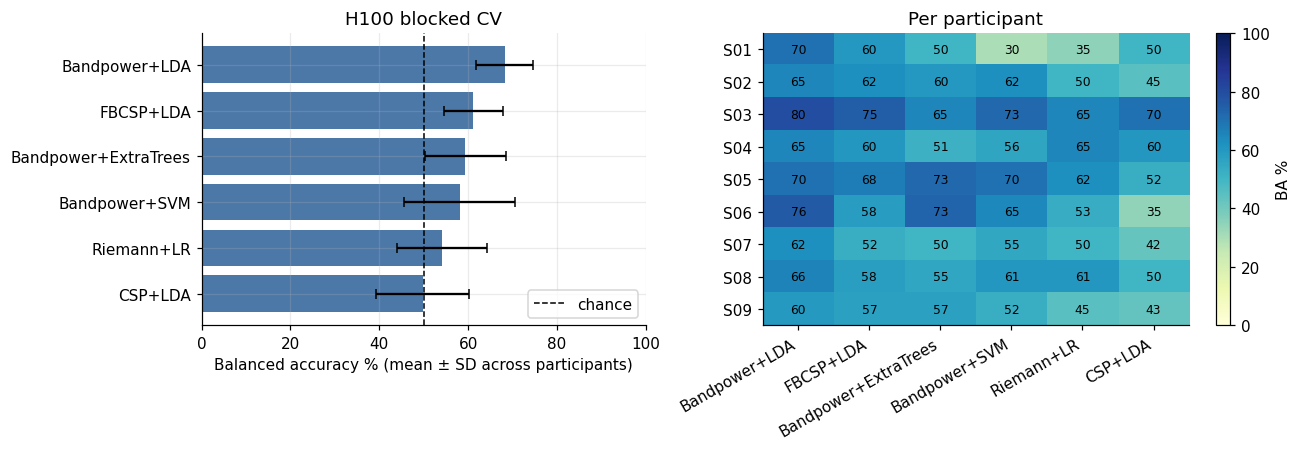

In [38]:
rows = []; PRED = {}
t0 = time.time()
for pid in PIDS:
    X, y = H[pid]['X'], H[pid]['y']
    for name, mk in MODELS.items():
        p = blocked_predict(mk, X, y); PRED[(pid, name)] = p
        ok = p >= 0
        rows.append(dict(participant=pid, model=name, BA=ba_valid(y, p), n_test=int(ok.sum()), n_correct=int((p[ok] == y[ok]).sum())))
RA = pd.DataFrame(rows); RA.to_csv(f'{OUT}/A_h100_blockedcv_per_participant.csv', index=False)
piv = RA.pivot(index='participant', columns='model', values='BA')[MNAMES] * 100
summ = pd.DataFrame({'mean_BA': piv.mean(), 'SD': piv.std(ddof=1), 'min': piv.min(), 'max': piv.max()}).round(1).sort_values('mean_BA', ascending=False)
summ.to_csv(f'{OUT}/A_h100_blockedcv_summary.csv'); print(f'Done in {time.time()-t0:.0f}s\n'); print(piv.round(1).to_string()); print('\n', summ.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.2]})
s2 = summ.iloc[::-1]; ax[0].barh(s2.index, s2.mean_BA, xerr=s2.SD, color='#4c78a8', capsize=3); ax[0].axvline(50, color='k', ls='--', lw=1, label='chance'); ax[0].set_xlim(0, 100); ax[0].set_xlabel('Balanced accuracy % (mean ± SD across participants)'); ax[0].set_title('H100 blocked CV'); ax[0].legend()
im = ax[1].imshow(piv[summ.index].values, cmap='YlGnBu', vmin=0, vmax=100, aspect='auto'); ax[1].set_xticks(range(len(summ))); ax[1].set_xticklabels(summ.index, rotation=30, ha='right'); ax[1].set_yticks(range(len(piv))); ax[1].set_yticklabels(piv.index); ax[1].grid(False)
for i in range(piv.shape[0]):
    for j in range(summ.shape[0]): ax[1].text(j, i, f'{piv[summ.index].values[i,j]:.0f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax[1], label='BA %'); ax[1].set_title('Per participant'); save_fig('A_h100_blockedcv')

### Statistics for Experiment A
1. **Per-participant significance:** exact binomial test of pooled accuracy against 50 % for the best model per participant (best model chosen *after* seeing the data → optimistic; so also reported for the pre-specified Bandpower+LDA).
2. **Group-level permutation test** (Bandpower+LDA): labels are shuffled within each participant, the full blocked-CV is repeated `N_PERM` times, and the mean-across-participants BA gives a null distribution.
3. **Model comparison:** Friedman test across models, then Wilcoxon signed-rank tests of each model against the best one with Holm correction.

participant         model   BA  n_test  p_binomial  acc_CI95_lo  acc_CI95_hi  significant_p<0.05
        S01 Bandpower+LDA 70.0      20      0.0577         48.1         85.5               False
        S02 Bandpower+LDA 65.0      40      0.0403         49.5         77.9                True
        S03 Bandpower+LDA 80.0      40      0.0001         65.2         89.5                True
        S04 Bandpower+LDA 64.9      43      0.0330         50.2         77.6                True
        S05 Bandpower+LDA 70.0      40      0.0083         54.6         81.9                True
        S06 Bandpower+LDA 76.0      34      0.0015         60.0         87.6                True
        S07 Bandpower+LDA 62.5      40      0.0769         47.0         75.8               False
        S08 Bandpower+LDA 65.8      38      0.0365         49.9         78.8                True
        S09 Bandpower+LDA 59.5      42      0.1400         44.5         73.0               False

Bandpower+LDA group mean BA =

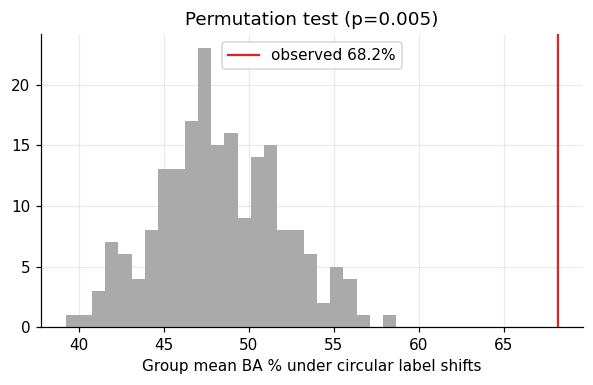


Friedman across 6 models: chi2=23.49, p=0.0003
    reference               versus  mean_diff_BA  p_wilcoxon  p_holm
Bandpower+LDA        Bandpower+SVM         -10.1      0.0078  0.0234
Bandpower+LDA Bandpower+ExtraTrees          -8.8      0.0117  0.0234
Bandpower+LDA              CSP+LDA         -18.4      0.0039  0.0195
Bandpower+LDA            FBCSP+LDA          -7.0      0.0039  0.0195
Bandpower+LDA           Riemann+LR         -14.1      0.0078  0.0234


In [39]:
from scipy.stats import binomtest, friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests
rows = []
for pid in PIDS:
    y = H[pid]['y']
    for name in ['Bandpower+LDA'] + [summ.index[0]] * (summ.index[0] != 'Bandpower+LDA'):
        r = RA[(RA.participant == pid) & (RA.model == name)].iloc[0]
        bt = binomtest(int(r.n_correct), int(r.n_test), 0.5, alternative='greater')
        lo, hi = binomtest(int(r.n_correct), int(r.n_test)).proportion_ci(0.95, method='wilson')
        rows.append(dict(participant=pid, model=name, BA=round(r.BA * 100, 1), n_test=int(r.n_test), p_binomial=bt.pvalue, acc_CI95_lo=round(lo * 100, 1), acc_CI95_hi=round(hi * 100, 1)))
PS = pd.DataFrame(rows); PS['significant_p<0.05'] = PS.p_binomial < .05; PS.to_csv(f'{OUT}/A_per_participant_significance.csv', index=False); print(PS.round(4).to_string(index=False))

# Group circular-shift test (preserves each participant's class-order pattern, unlike full label shuffling).
# This is exploratory with nine subjects and short, temporally correlated recordings.
bp = BandPower(); FEAT = {pid: bp.transform(H[pid]['X']) for pid in PIDS}
mk_clf = lambda: Pipeline([('s', StandardScaler()), ('c', LDA(solver='lsqr', shrinkage='auto'))])
def mean_ba_perm(rng):
    out = []
    for pid in PIDS:
        yy = np.roll(H[pid]['y'], int(rng.integers(1, len(H[pid]['y'])))); out.append(ba_valid(yy, blocked_predict(mk_clf, FEAT[pid], yy)))
    return np.nanmean(out)
obs = np.nanmean([ba_valid(H[pid]['y'], blocked_predict(mk_clf, FEAT[pid], H[pid]['y'])) for pid in PIDS])
rng = np.random.default_rng(RANDOM_STATE); null = np.array([mean_ba_perm(rng) for _ in range(N_PERM)])
p_perm = (1 + (null >= obs).sum()) / (1 + N_PERM)
print(f'\nBandpower+LDA group mean BA = {obs*100:.1f}%  | permutation null mean {null.mean()*100:.1f}% (95th pct {np.percentile(null,95)*100:.1f}%) | p = {p_perm:.4f} ({N_PERM} permutations)')
plt.figure(figsize=(5.5, 3.6)); plt.hist(null * 100, 25, color='#aaa'); plt.axvline(obs * 100, color='C3', label=f'observed {obs*100:.1f}%'); plt.xlabel('Group mean BA % under circular label shifts'); plt.legend(); plt.title(f'Permutation test (p={p_perm:.3f})'); save_fig('A_permutation_test')
json.dump(dict(observed=obs, null_mean=float(null.mean()), null_p95=float(np.percentile(null, 95)), p=p_perm, n_perm=N_PERM), open(f'{OUT}/A_permutation_test.json', 'w'))

fr = friedmanchisquare(*[piv[m].values for m in MNAMES]); print(f'\nFriedman across {len(MNAMES)} models: chi2={fr.statistic:.2f}, p={fr.pvalue:.4f}')
reference = 'Bandpower+LDA'; comp = []
for m in MNAMES:
    if m == reference: continue
    diff = piv[m].values - piv[reference].values
    try: p_value = wilcoxon(diff).pvalue if np.any(diff != 0) else 1.0
    except ValueError: p_value = 1.0
    comp.append((m, p_value, float(np.mean(diff))))
adj = multipletests([item[1] for item in comp], method='holm')[1]
CMP = pd.DataFrame([dict(reference=reference, versus=item[0], mean_diff_BA=round(item[2], 1), p_wilcoxon=item[1], p_holm=adj_p) for item, adj_p in zip(comp, adj)])
CMP.to_csv(f'{OUT}/A_model_comparison.csv', index=False); print(CMP.round(4).to_string(index=False))

### Negative controls for H100

Predict from trial order and from EEG before the imagery cue using the same blocked folds. A high control score limits the motor-imagery interpretation.


In [40]:
# Controls using the same blocked folds as Experiment A.
# Trial index/parity can reveal predictable cue order; pre-cue power can reveal preparation/drift.
control_rows = []
for pid in PIDS:
    y = H[pid]['y']; idx = H[pid]['idx']; n = len(y)
    order_f = np.column_stack([np.arange(n), np.arange(n) % 2, idx / FS])
    order_model = lambda: ExtraTreesClassifier(200, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
    order_pred = blocked_predict(order_model, order_f, y)
    control_rows.append(dict(participant=pid, control='trial order only', BA=ba_valid(y, order_pred)))
    sig = H[pid]['raw'][:, H[pid]['i3']]
    pre = np.array([sig[i - int(1.5*FS):i - int(.5*FS)].T for i in idx])
    pre_f = BandPower(nperseg=125).transform(pre)
    pre_pred = blocked_predict(mk_clf, pre_f, y)
    control_rows.append(dict(participant=pid, control='pre-cue EEG only', BA=ba_valid(y, pre_pred)))
CTRL = pd.DataFrame(control_rows)
CTRL.to_csv(f'{OUT}/A_negative_controls.csv', index=False)
print('Blocked-CV negative controls (mean balanced accuracy):')
print((CTRL.groupby('control').BA.mean()*100).round(1).to_string())
print('Any control near or above the EEG model score needs investigation and discussion.')


Blocked-CV negative controls (mean balanced accuracy):
control
pre-cue EEG only    52.1
trial order only    43.1
Any control near or above the EEG model score needs investigation and discussion.


## 5. Experiment B — ERD/ERS physiology check (H100)
Do the signals show the expected motor-cortex pattern? Event-related desynchronization (ERD) = fall in mu (8–12 Hz) / beta (16–26 Hz) power relative to a pre-cue baseline.
Expected: right-hand imagery → stronger ERD at C3 than C4; left-hand imagery → stronger ERD at C4 than C3. Baseline = −1.0…0 s before Start (**assumption: check that the baseline is a rest period in your protocol**).
`LAT = (ERD_C3 − ERD_C4)[right] − (ERD_C3 − ERD_C4)[left]` is expected to be **negative**.
Caveat: `F-C3`/`F-C4` may be FC3/FC4, so lateralisation may be weaker than for true C3/C4.

         band participant  ERD_C3_left  ERD_C4_left  ERD_C3_right  ERD_C4_right      LAT
   mu 8-12 Hz         S01       2024.6     187616.8       13747.8       10054.2 189285.9
   mu 8-12 Hz         S02      62599.7      24289.3       75927.0        8994.6  28622.1
   mu 8-12 Hz         S03        742.5      14362.0        1490.2        4358.1  10751.6
   mu 8-12 Hz         S04       4509.4       1989.0       26444.7        1131.4  22792.9
   mu 8-12 Hz         S05     164746.9      56252.8      400966.6       17141.1 275331.4
   mu 8-12 Hz         S06      62318.3       3340.7      236342.9        2177.3 175188.0
   mu 8-12 Hz         S07     169240.4      15106.7      181289.9       13961.5  13194.7
   mu 8-12 Hz         S08      24173.1     103360.4      110136.3       97246.1  92077.5
   mu 8-12 Hz         S09      26497.4      48806.0      580900.0       77348.9 525859.7
beta 16-26 Hz         S01        -94.7        -62.3         -96.6         -95.9     31.6
beta 16-26 Hz        

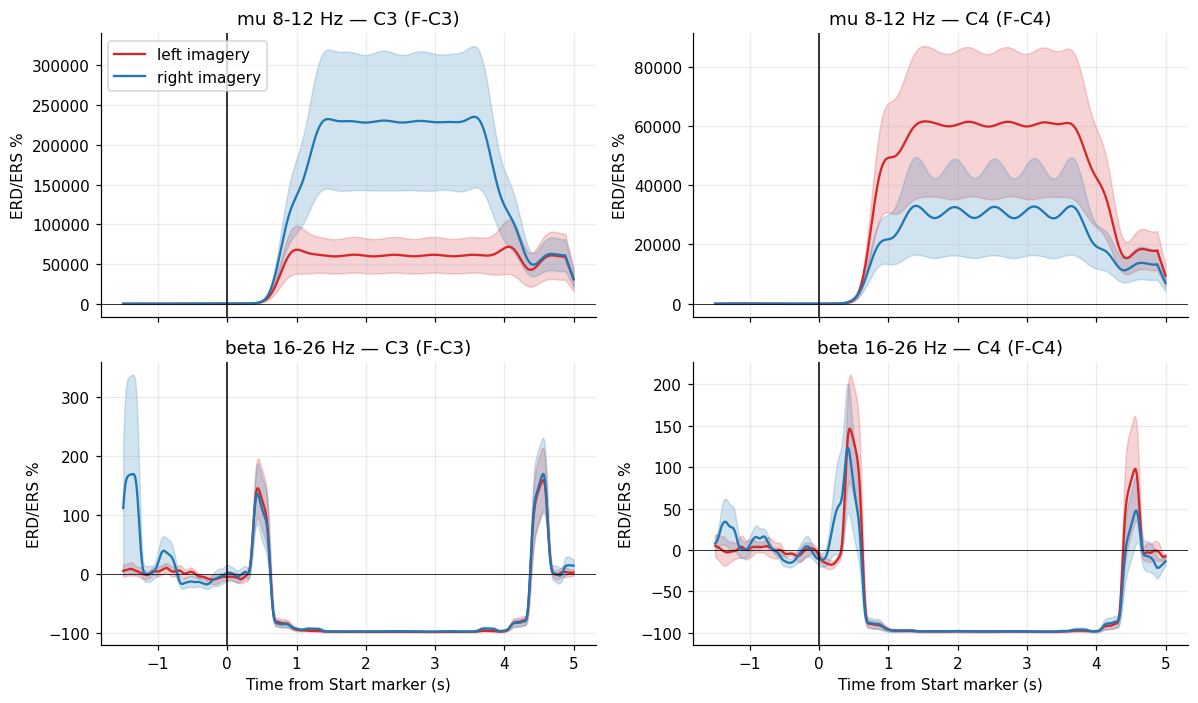

In [41]:
def erd_curves(pid, lo, hi, pre=1.5, post=5.0, base=(-1.0, 0.0), smooth=0.25):
    sig = H[pid]['raw'][:, H[pid]['i3']]; env = np.abs(hilbert(band_filter_cont(sig, lo, hi), axis=0)) ** 2
    t = np.arange(-int(pre * FS), int(post * FS)) / FS; res = {}
    ok = [i for i in range(len(H[pid]['idx'])) if H[pid]['idx'][i] - int(pre * FS) >= 0 and H[pid]['idx'][i] + int(post * FS) <= len(env)]
    for c in (0, 1):
        eps = np.array([env[H[pid]['idx'][i] - int(pre * FS): H[pid]['idx'][i] + int(post * FS)].T for i in ok if H[pid]['y'][i] == c])
        if len(eps) == 0: return None, None
        P = eps.mean(0); b = P[:, (t >= base[0]) & (t < base[1])].mean(1, keepdims=True); E = (P / b - 1) * 100
        k = int(smooth * FS); E = np.array([np.convolve(e, np.ones(k) / k, mode='same') for e in E]); res[c] = E
    return t, res
ERD = {}
for band_name, (lo, hi) in {'mu 8-12 Hz': (8, 12), 'beta 16-26 Hz': (16, 26)}.items():
    ERD[band_name] = {pid: erd_curves(pid, lo, hi) for pid in PIDS}
lat_rows = []
for band_name in ERD:
    for pid in PIDS:
        t, r = ERD[band_name][pid]
        if r is None: continue
        win = (t >= .5) & (t <= 4.5); m = {c: r[c][:, win].mean(1) for c in (0, 1)}   # [C3, Cz, C4]
        lat = (m[1][0] - m[1][2]) - (m[0][0] - m[0][2])
        lat_rows.append(dict(band=band_name, participant=pid, ERD_C3_left=m[0][0], ERD_C4_left=m[0][2], ERD_C3_right=m[1][0], ERD_C4_right=m[1][2], LAT=lat))
LAT = pd.DataFrame(lat_rows); LAT.round(2).to_csv(f'{OUT}/B_erd_lateralisation.csv', index=False); print(LAT.round(1).to_string(index=False))
lat_stats = []
for band_name in ERD:
    v = LAT[LAT.band == band_name].LAT.values; w = wilcoxon(v, alternative='less') if len(v) > 4 else None
    lat_stats.append(dict(band=band_name, n=len(v), median_LAT=float(np.median(v)), n_negative=int((v < 0).sum()), p_wilcoxon_less=float(w.pvalue) if w else np.nan))
print('\n', pd.DataFrame(lat_stats).round(4).to_string(index=False)); pd.DataFrame(lat_stats).to_csv(f'{OUT}/B_lateralisation_stats.csv', index=False)
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for r_i, band_name in enumerate(ERD):
    for c_i, (ch_i, ch_n) in enumerate([(0, 'C3 (F-C3)'), (2, 'C4 (F-C4)')]):
        ax = axs[r_i, c_i]
        for cls, col, lab in [(0, '#d62728', 'left imagery'), (1, '#1f77b4', 'right imagery')]:
            cur = np.array([ERD[band_name][p][1][cls][ch_i] for p in PIDS if ERD[band_name][p][1] is not None]); t = ERD[band_name][PIDS[0]][0]
            m, se = cur.mean(0), cur.std(0, ddof=1) / np.sqrt(len(cur)); ax.plot(t, m, color=col, label=lab); ax.fill_between(t, m - se, m + se, color=col, alpha=.2)
        ax.axvline(0, color='k', lw=1); ax.axhline(0, color='k', lw=.5); ax.set_title(f'{band_name} — {ch_n}'); ax.set_ylabel('ERD/ERS %')
        if r_i == 1: ax.set_xlabel('Time from Start marker (s)')
        if r_i == 0 and c_i == 0: ax.legend()
save_fig('B_erd_timecourse')

## 6. Experiment C — time-resolved decoding (H100)
1-s windows slid in 0.25-s steps across the 4-s epoch; Bandpower+LDA with the same blocked CV. Shows *when* class information appears and gives the Wolpaw information-transfer rate in bits/trial (N=2).

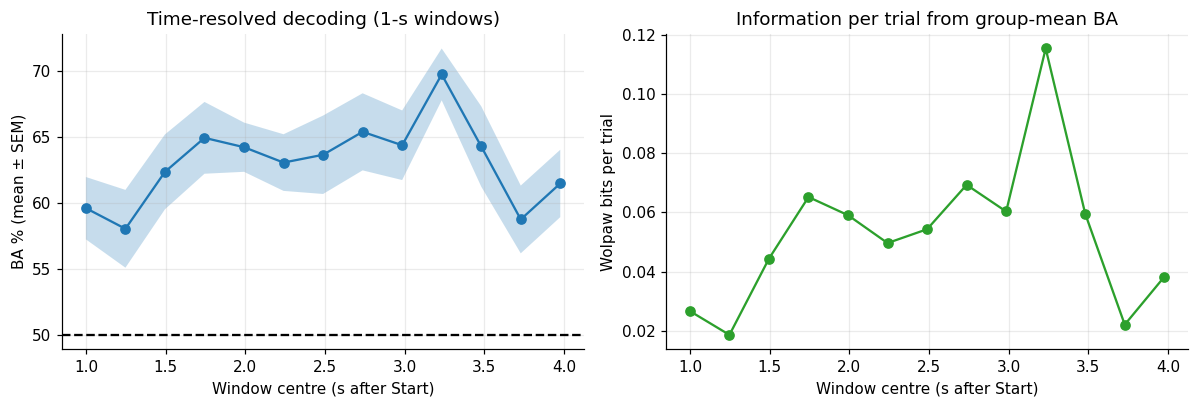

window_centre_s_after_start
1.000    59.6
1.248    58.0
1.496    62.3
1.744    64.9
1.992    64.2
2.240    63.0
2.488    63.6
2.736    65.4
2.984    64.4
3.232    69.7
3.480    64.3
3.728    58.7
3.976    61.5


In [42]:
def wolpaw_bits(P, N=2):
    P = np.clip(P, 1e-9, 1 - 1e-9); return np.log2(N) + P * np.log2(P) + (1 - P) * np.log2((1 - P) / (N - 1))
starts = np.arange(0, N_SAMP - FS + 1, FS // 4); curves = {pid: [] for pid in PIDS}
bpw = BandPower(nperseg=125)
for pid in PIDS:
    X, y = H[pid]['X'], H[pid]['y']
    for s in starts:
        F = bpw.transform(X[:, :, s:s + FS]); curves[pid].append(ba_valid(y, blocked_predict(mk_clf, F, y)))
TR = pd.DataFrame(curves, index=(starts + FS / 2) / FS + TMIN) * 100; TR.index.name = 'window_centre_s_after_start'; TR.round(1).to_csv(f'{OUT}/C_time_resolved.csv')
mean, se = TR.mean(1), TR.std(1, ddof=1) / np.sqrt(TR.shape[1])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); ax[0].plot(TR.index, mean, 'o-'); ax[0].fill_between(TR.index, mean - se, mean + se, alpha=.25); ax[0].axhline(50, color='k', ls='--'); ax[0].set_xlabel('Window centre (s after Start)'); ax[0].set_ylabel('BA % (mean ± SEM)'); ax[0].set_title('Time-resolved decoding (1-s windows)')
ax[1].plot(TR.index, wolpaw_bits(mean / 100), 'o-', color='C2'); ax[1].set_xlabel('Window centre (s after Start)'); ax[1].set_ylabel('Wolpaw bits per trial'); ax[1].set_title('Information per trial from group-mean BA'); save_fig('C_time_resolved')
print(TR.mean(1).round(1).to_string())

## 7. Experiment D — public benchmark: classical models vs EEGNet
Cross-session (train sessions 0–2, test 3–4, per subject) and leave-one-subject-out. EEGNet (Lawhern et al. 2018) is a compact CNN: temporal convolution (learns frequency filters), depthwise spatial convolution (learns channel weights),
separable convolution, then a linear classifier. Trained here on trials scaled per subject (divide by the subject's overall std).

device cuda
LOSO subject 1 97s
LOSO subject 2 138s
LOSO subject 3 178s
LOSO subject 4 219s
LOSO subject 5 259s
LOSO subject 6 300s
LOSO subject 7 340s
LOSO subject 8 380s
LOSO subject 9 420s
     protocol                model  mean  std
         LOSO               EEGNet  71.3  8.6
         LOSO        Bandpower+LDA  70.4  9.8
         LOSO            FBCSP+LDA  69.4  8.5
         LOSO              CSP+LDA  69.3  8.5
         LOSO           Riemann+LR  67.9  9.6
         LOSO Bandpower+ExtraTrees  67.2 10.0
         LOSO        Bandpower+SVM  65.9  9.9
cross-session               EEGNet  79.2 16.9
cross-session            FBCSP+LDA  77.0 13.6
cross-session        Bandpower+LDA  76.6 13.3
cross-session           Riemann+LR  74.0 15.2
cross-session        Bandpower+SVM  73.7 13.7
cross-session              CSP+LDA  73.6 13.9
cross-session Bandpower+ExtraTrees  73.1 15.9


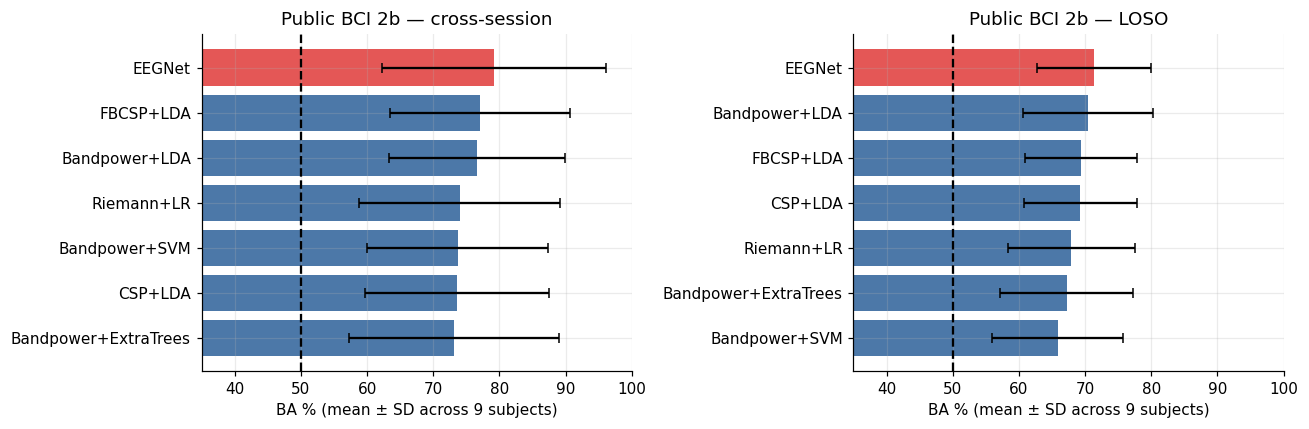

cross-session: EEGNet vs best classical (FBCSP+LDA): diff +2.2 BA points, Wilcoxon p=0.238
LOSO: EEGNet vs best classical (Bandpower+LDA): diff +0.9 BA points, Wilcoxon p=0.496


In [43]:
import torch, torch.nn as nn, torch.nn.functional as Fnn
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'; print('device', DEV)
class EEGNet(nn.Module):
    def __init__(s, n_ch=3, n_t=N_SAMP, F1=8, D=2, F2=16, k1=64, k3=16, p=0.5):
        super().__init__()
        s.b1 = nn.Sequential(nn.Conv2d(1, F1, (1, k1), padding=(0, k1 // 2), bias=False), nn.BatchNorm2d(F1), nn.Conv2d(F1, F1 * D, (n_ch, 1), groups=F1, bias=False), nn.BatchNorm2d(F1 * D), nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(p))
        s.b2 = nn.Sequential(nn.Conv2d(F1 * D, F1 * D, (1, k3), padding=(0, k3 // 2), groups=F1 * D, bias=False), nn.Conv2d(F1 * D, F2, 1, bias=False), nn.BatchNorm2d(F2), nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(p))
        with torch.no_grad(): d = s.b2(s.b1(torch.zeros(1, 1, n_ch, n_t))).numel()
        s.fc = nn.Linear(d, 2)
    def forward(s, x): return s.fc(s.b2(s.b1(x.unsqueeze(1))).flatten(1))
def scale_subject(X): return (X / (X.std() + 1e-12)).astype(np.float32)
def train_eegnet(Xtr, ytr, epochs, model=None, lr=1e-3, seed=0, bs=32, shift=25):
    torch.manual_seed(seed); np.random.seed(seed)
    m = model if model is not None else EEGNet(Xtr.shape[1]); m = m.to(DEV); opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=1e-4)
    Xt = torch.tensor(Xtr, dtype=torch.float32, device=DEV); yt = torch.tensor(ytr, dtype=torch.long, device=DEV); n = len(yt)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(n, device=DEV)
        for i in range(0, n, bs):
            b = perm[i:i + bs]
            if len(b) < 2: continue
            xb = Xt[b]; sh = int(np.random.randint(-shift, shift + 1)); xb = torch.roll(xb, sh, dims=-1) + 0.05 * torch.randn_like(xb)
            opt.zero_grad(); loss = Fnn.cross_entropy(m(xb), yt[b]); loss.backward(); opt.step()
    return m
@torch.no_grad()
def predict_eegnet(m, X):
    m.eval(); out = []
    Xt = torch.tensor(X, dtype=torch.float32, device=DEV)
    for i in range(0, len(Xt), 256): out.append(m(Xt[i:i + 256]).argmax(1).cpu().numpy())
    return np.concatenate(out)

def per_subject_scaled(X, s):
    Xs = X.copy().astype(np.float64)
    for u in np.unique(s): Xs[s == u] = Xs[s == u] / (Xs[s == u].std() + 1e-30)
    return Xs
XPs = per_subject_scaled(XP, sP)   # public source pool used for H100 transfer only
# Public benchmark below scales each fold from its training data; held-out sessions/people do not set the scale.
subs = sorted(set(sP)); res_pub = []
t0 = time.time()
for u in subs:                                              # cross-session
    tr = (sP == u) & (seP <= 2); te = (sP == u) & (seP >= 3)
    fold_scale = XP[tr].std() + 1e-30; Xtr = XP[tr] / fold_scale; Xte = XP[te] / fold_scale
    for name, mk in MODELS.items():
        m = mk().fit(Xtr, yP[tr]); res_pub.append(dict(protocol='cross-session', subject=u, model=name, BA=BA(yP[te], m.predict(Xte))))
    if RUN_EEGNET_PUBLIC:
        bas = [BA(yP[te], predict_eegnet(train_eegnet(Xtr.astype(np.float32), yP[tr], EEG_EPOCHS_FT, seed=sd), Xte.astype(np.float32))) for sd in SEEDS]
        res_pub.append(dict(protocol='cross-session', subject=u, model='EEGNet', BA=float(np.mean(bas))))
for u in subs:                                              # leave-one-subject-out
    tr = sP != u; te = sP == u
    fold_scale = XP[tr].std() + 1e-30; Xtr = XP[tr] / fold_scale; Xte = XP[te] / fold_scale
    for name, mk in MODELS.items():
        m = mk().fit(Xtr, yP[tr]); res_pub.append(dict(protocol='LOSO', subject=u, model=name, BA=BA(yP[te], m.predict(Xte))))
    if RUN_EEGNET_PUBLIC:
        bas = [BA(yP[te], predict_eegnet(train_eegnet(Xtr.astype(np.float32), yP[tr], EEG_EPOCHS_PRE, seed=sd), Xte.astype(np.float32))) for sd in SEEDS[:1]]
        res_pub.append(dict(protocol='LOSO', subject=u, model='EEGNet', BA=float(np.mean(bas))))
    print('LOSO subject', u, f'{time.time()-t0:.0f}s')
RP = pd.DataFrame(res_pub); RP.to_csv(f'{OUT}/D_public_per_subject.csv', index=False)
sp = RP.groupby(['protocol', 'model']).BA.agg(['mean', 'std']).mul(100).round(1).reset_index().sort_values(['protocol', 'mean'], ascending=[True, False]); sp.to_csv(f'{OUT}/D_public_summary.csv', index=False); print(sp.to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, proto in zip(axs, ['cross-session', 'LOSO']):
    d = sp[sp.protocol == proto].iloc[::-1]; ax.barh(d.model, d['mean'], xerr=d['std'], color=['#e45756' if m == 'EEGNet' else '#4c78a8' for m in d.model], capsize=3); ax.axvline(50, color='k', ls='--'); ax.set_xlim(35, 100); ax.set_title(f'Public BCI 2b — {proto}'); ax.set_xlabel('BA % (mean ± SD across 9 subjects)')
save_fig('D_public_models')
# stats: EEGNet vs best classical per protocol
for proto in ['cross-session', 'LOSO']:
    pv = RP[RP.protocol == proto].pivot(index='subject', columns='model', values='BA')
    if 'EEGNet' in pv:
        bc = pv.drop(columns='EEGNet').mean().idxmax(); w = wilcoxon(pv['EEGNet'], pv[bc]); print(f'{proto}: EEGNet vs best classical ({bc}): diff {100*(pv["EEGNet"]-pv[bc]).mean():+.1f} BA points, Wilcoxon p={w.pvalue:.3f}')

## 8. Experiment E — transfer from the public benchmark to the H100 headset (**main novelty**)
*Question: how many labelled calibration trials does the H100 need, and does public pretraining help?*
Same blocked CV as Experiment A. In each fold the H100 test block is never used for fitting. The calibration set is the first *k* trials (in time order) of the training blocks.

| Method | Uses public data? | Uses H100 labels? |
|---|---|---|
| H100-only Bandpower+LDA | no | k trials |
| H100-only EEGNet (scratch) | no | k trials |
| Public EEGNet, zero-shot | yes (trained once on all 9 public subjects) | none (k=0) |
| Public EEGNet + fine-tune | yes | k trials |
| Riemann+LR on public data, **no** alignment, zero-shot | yes | none |
| Riemann+LR on public data, **with** Riemannian alignment (RA), zero-shot | yes | none; *unlabelled* training-block trials are used only to centre the covariances |
| Riemann+LR RA: public + k labelled H100 trials | yes | k trials |

All H100 trials are scaled per participant (divide by overall std). Public EEGNet is pretrained once on *all* public subjects — the public dataset is a different source, so this is not leakage of H100 test data.

Pretrained EEGNet on public data in 20s
S01 38s
S02 52s
S03 67s
S04 83s
S05 98s
S06 113s
S07 127s
S08 142s
S09 157s
k_label                                      0     5    10    20   all
method                                                                
H100-only Bandpower+LDA                    NaN  57.7  63.9  65.4  68.2
H100-only EEGNet (scratch)                 NaN  56.9  59.1  59.4  59.4
Public EEGNet (zero-shot)                 49.9   NaN   NaN   NaN   NaN
Public EEGNet + fine-tune                  NaN  55.3  53.7  54.9  55.1
Riemann RA: public + H100 labels           NaN  39.0  38.1  41.7  40.9
Riemann public + RA (zero-shot)           40.4   NaN   NaN   NaN   NaN
Riemann public, no alignment (zero-shot)  43.5   NaN   NaN   NaN   NaN


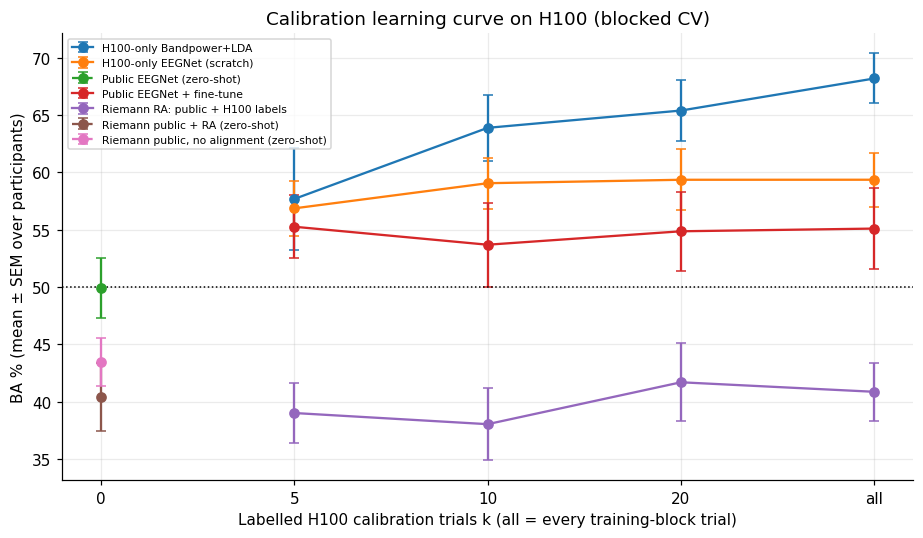

  k                           method  mean_diff_BA_points  n  p_wilcoxon  p_holm
  5       H100-only EEGNet (scratch)                 -0.8  9      1.0000  1.0000
  5        Public EEGNet + fine-tune                 -2.4  9      0.5703  1.0000
  5 Riemann RA: public + H100 labels                -18.7  9      0.0078  0.0781
 10       H100-only EEGNet (scratch)                 -4.8  9      0.0312  0.1562
 10        Public EEGNet + fine-tune                -10.2  9      0.0469  0.1875
 10 Riemann RA: public + H100 labels                -25.8  9      0.0039  0.0469
 20       H100-only EEGNet (scratch)                 -6.0  8      0.0156  0.0938
 20        Public EEGNet + fine-tune                -10.5  8      0.0938  0.2812
 20 Riemann RA: public + H100 labels                -23.7  8      0.0078  0.0781
all       H100-only EEGNet (scratch)                 -8.8  9      0.0078  0.0781
all        Public EEGNet + fine-tune                -13.1  9      0.0117  0.0820
all Riemann RA: public + H10

In [44]:
t0 = time.time()
torch.manual_seed(0)
pre_model = train_eegnet(XPs.astype(np.float32), yP, EEG_EPOCHS_PRE, seed=0)
print(f'Pretrained EEGNet on public data in {time.time()-t0:.0f}s')
pre_state = {k: v.detach().cpu().clone() for k, v in pre_model.state_dict().items()}
def fresh_pre():
    m = EEGNet(3); m.load_state_dict(pre_state); return m

def align_cov(C, ref): R = invsqrtm(ref); return np.array([R @ c @ R.T for c in C])
cov_est = Covariances(estimator='oas')
COV_P = np.zeros((len(yP), 3, 3))
for u in subs:
    C = cov_est.transform(XPs[sP == u]); COV_P[sP == u] = align_cov(C, mean_riemann(C))
COV_P_raw = cov_est.transform(XPs)
ts_al = TangentSpace().fit(COV_P); ts_raw = TangentSpace().fit(COV_P_raw)
clf_al = Pipeline([('s', StandardScaler()), ('c', LogisticRegression(max_iter=1000))]).fit(ts_al.transform(COV_P), yP)
clf_raw = Pipeline([('s', StandardScaler()), ('c', LogisticRegression(max_iter=1000))]).fit(ts_raw.transform(COV_P_raw), yP)

def calib_subset(tr, k, y):
    if k == 'all': return tr
    # k counts total labelled target trials; sample balanced classes from training indices only.
    left, right = tr[y[tr] == 0], tr[y[tr] == 1]
    a, b = (k + 1) // 2, k // 2
    if len(left) < a or len(right) < b: return None
    return np.sort(np.r_[left[:a], right[:b]])

rows = []
ks_label = lambda k: 100000 if k == 'all' else k
for pid in PIDS:
    Xh_raw = H[pid]['X'].astype(np.float64); y = H[pid]['y']; n = len(y); folds = np.array_split(np.arange(n), K_FOLDS)
    preds = {}   # (method, k) -> array of predictions
    for te in folds:
        lo, hi = te[0], te[-1]; tr = np.array([i for i in range(n) if i < lo - GAP or i > hi + GAP])
        # The held-out fold cannot influence normalization or alignment.
        target_scale = Xh_raw[tr].std() + 1e-30
        Xh = Xh_raw / target_scale
        C_h = cov_est.transform(Xh)
        ref = mean_riemann(C_h[tr]); C_al = align_cov(C_h, ref)
        for name, clf_ts in [('Riemann public, no alignment (zero-shot)', None), ('Riemann public + RA (zero-shot)', None)]:
            key = (name, 0); preds.setdefault(key, np.full(n, -1))
            preds[key][te] = (clf_raw.predict(ts_raw.transform(C_h[te])) if 'no alignment' in name else clf_al.predict(ts_al.transform(C_al[te])))
        key = ('Public EEGNet (zero-shot)', 0); preds.setdefault(key, np.full(n, -1)); preds[key][te] = predict_eegnet(pre_model, Xh[te].astype(np.float32))
        for k in CALIB_SIZES:
            if k == 0: continue
            cs = calib_subset(tr, k, y)
            if cs is None: continue
            kk = ks_label(k)
            # H100-only Bandpower+LDA
            key = ('H100-only Bandpower+LDA', kk); preds.setdefault(key, np.full(n, -1))
            m = MODELS['Bandpower+LDA']().fit(Xh[cs], y[cs]); preds[key][te] = m.predict(Xh[te])
            # Riemann RA public + k labelled H100
            key = ('Riemann RA: public + H100 labels', kk); preds.setdefault(key, np.full(n, -1))
            F = np.vstack([ts_al.transform(COV_P), ts_al.transform(C_al[cs])]); yy = np.r_[yP, y[cs]]; w = np.r_[np.ones(len(yP)), np.full(len(cs), max(1.0, len(yP) / (10 * len(cs))))]
            sc = StandardScaler().fit(F); lr = LogisticRegression(max_iter=1000).fit(sc.transform(F), yy, sample_weight=w); preds[key][te] = lr.predict(sc.transform(ts_al.transform(C_al[te])))
            # EEGNet scratch + fine-tune (avg over seeds via majority of probabilities -> use mean of seed predictions)
            for key_name, builder in [('H100-only EEGNet (scratch)', lambda: None), ('Public EEGNet + fine-tune', fresh_pre)]:
                key = (key_name, kk); preds.setdefault(key, np.full(n, -1)); votes = []
                for sd in SEEDS:
                    base = builder()
                    mm = train_eegnet(Xh[cs].astype(np.float32), y[cs], EEG_EPOCHS_FT, model=base, lr=1e-3 if base is None else 3e-4, seed=sd)
                    votes.append(predict_eegnet(mm, Xh[te].astype(np.float32)))
                preds[key][te] = (np.mean(votes, 0) >= 0.5).astype(int)
    for (meth, k), p in preds.items(): rows.append(dict(participant=pid, method=meth, k=k, BA=ba_valid(y, p)))
    print(pid, f'{time.time()-t0:.0f}s')
RE = pd.DataFrame(rows); RE['k_label'] = RE.k.map(lambda k: 'all' if k == 100000 else str(k)); RE.to_csv(f'{OUT}/E_transfer_per_participant.csv', index=False)
tab = RE.groupby(['method', 'k_label']).BA.agg(['mean', 'std', 'count']).reset_index(); tab[['mean', 'std']] *= 100
order_k = ['0', '5', '10', '20', 'all']; ptab = tab.pivot(index='method', columns='k_label', values='mean')[[c for c in order_k if c in tab.k_label.unique()]].round(1)
print(ptab.to_string()); ptab.to_csv(f'{OUT}/E_transfer_summary_mean_BA.csv'); tab.round(2).to_csv(f'{OUT}/E_transfer_summary_long.csv', index=False)

fig, ax = plt.subplots(figsize=(8.5, 5)); xs = {k: i for i, k in enumerate(order_k)}
for meth, g in RE.groupby('method'):
    g2 = g.groupby('k_label').BA.agg(['mean', 'std', 'count']); g2 = g2.reindex([k for k in order_k if k in g2.index])
    xv = [xs[k] for k in g2.index]; ls = '--' if 'zero-shot' in meth else '-'; ax.errorbar(xv, g2['mean'] * 100, yerr=g2['std'] / np.sqrt(g2['count']) * 100, marker='o', capsize=3, ls=ls, label=meth)
ax.axhline(50, color='k', lw=1, ls=':'); ax.set_xticks(range(len(order_k))); ax.set_xticklabels(order_k); ax.set_xlabel('Labelled H100 calibration trials k (all = every training-block trial)'); ax.set_ylabel('BA % (mean ± SEM over participants)'); ax.set_title('Calibration learning curve on H100 (blocked CV)'); ax.legend(fontsize=7, loc='best'); save_fig('E_transfer_learning_curve')

# paired tests at each k against H100-only Bandpower+LDA
cmp_rows = []
for k in order_k:
    pv = RE[RE.k_label == k].pivot(index='participant', columns='method', values='BA')
    if 'H100-only Bandpower+LDA' not in pv: continue
    for meth in pv.columns:
        if meth == 'H100-only Bandpower+LDA': continue
        d = (pv[meth] - pv['H100-only Bandpower+LDA']).dropna()
        if len(d) > 4 and np.any(d != 0): cmp_rows.append(dict(k=k, method=meth, mean_diff_BA_points=round(d.mean() * 100, 1), n=len(d), p_wilcoxon=wilcoxon(d).pvalue))
        # zero-shot rows only exist at k=0
if cmp_rows:
    CE = pd.DataFrame(cmp_rows); CE['p_holm'] = multipletests(CE.p_wilcoxon, method='holm')[1]; CE.to_csv(f'{OUT}/E_transfer_paired_tests.csv', index=False); print(CE.round(4).to_string(index=False))
# zero-shot methods vs chance
zs = RE[RE.k == 0].pivot(index='participant', columns='method', values='BA')
print('\nZero-shot methods vs chance (one-sample Wilcoxon on participant BA - 0.5):')
for c in zs.columns:
    v = (zs[c] - .5).dropna(); print(f'  {c}: mean {zs[c].mean()*100:.1f}%  p={wilcoxon(v, alternative="greater").pvalue:.3f}')

## 9. Experiment F — channel ablation (only if `CH_ALL` was set)

In [45]:
if len(CH_ALL) > 3 and all(H[p]['Xall'] is not None for p in PIDS):
    rows = []
    for pid in PIDS:
        y = H[pid]['y']
        for label, Xv in [('3 channels (C3/Cz/C4 labels)', H[pid]['X']), (f'all {len(CH_ALL)} channels', H[pid]['Xall'])]:
            mods = make_models(Xv.shape[1])
            for name in ['Bandpower+LDA', 'FBCSP+LDA', 'Riemann+LR']:
                rows.append(dict(participant=pid, channels=label, model=name, BA=ba_valid(y, blocked_predict(mods[name], Xv, y))))
    RF = pd.DataFrame(rows); RF.to_csv(f'{OUT}/F_channel_ablation.csv', index=False)
    print((RF.pivot_table(index='model', columns='channels', values='BA') * 100).round(1).to_string())
    for name in ['Bandpower+LDA', 'FBCSP+LDA', 'Riemann+LR']:
        pv = RF[RF.model == name].pivot(index='participant', columns='channels', values='BA'); d = pv.iloc[:, 1] - pv.iloc[:, 0]
        print(f'{name}: all-channel minus 3-channel = {d.mean()*100:+.1f} points, Wilcoxon p={wilcoxon(d).pvalue:.3f}')
else:
    print('Channel ablation skipped (set CH_ALL to the full list of EEG column names to enable).')

Channel ablation skipped (set CH_ALL to the full list of EEG column names to enable).


## 10. Additional H100 checks: new-person generalization and signal audit

These analyses use the same H100 participants loaded above. The leave-one-participant-out (LOPO) classical models train on eight participants and test on the ninth. The primary classical models do not fit on the held-out participant. The aligned Riemannian row is a separate **unsupervised, transductive** result: it uses the held-out participant’s unlabeled covariance distribution for alignment, so it is not a strict zero-adaptation new-person test. Treat the nine held-out participants as the group-level units; the p-values are exploratory with this small sample.


LOPO participant balanced accuracy (%)
model    Bandpower+ExtraTrees  Bandpower+LDA  Bandpower+SVM  CSP+LDA  FBCSP+LDA  Riemann+LR  Riemann+LR (unlabeled target alignment)
heldout                                                                                                                             
S01                      65.0           70.0           75.0     50.0       70.0        55.0                                     65.0
S02                      67.5           75.0           75.0     60.0       75.0        62.5                                     65.0
S03                      75.0           82.5           82.5     57.5       75.0        60.0                                     65.0
S04                      63.1           72.1           67.7     56.1       58.8        69.8                                     62.9
S05                      77.5           77.5           75.0     57.5       75.0        67.5                                     62.5
S06                      70.5 

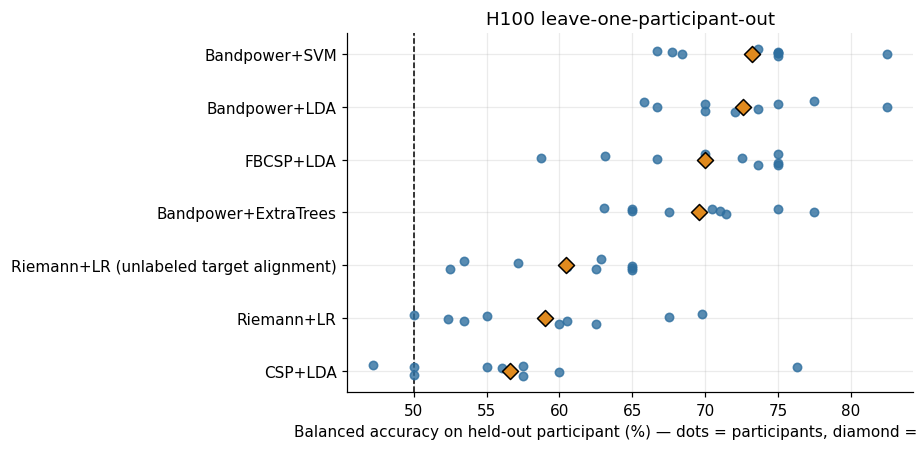

In [46]:
# Cell 10A — H100 leave-one-participant-out (LOPO)
from scipy.stats import wilcoxon

# Primary LOPO results use the original arrays and fit each model on eight people only.
# The aligned Riemannian variant below is explicitly transductive: it uses unlabeled
# covariance data from the held-out person's complete recording for alignment.
rows = []
for heldout in PIDS:
    train_pids = [pid for pid in PIDS if pid != heldout]
    Xtr = np.concatenate([H[pid]['X'] for pid in train_pids], axis=0)
    ytr = np.concatenate([H[pid]['y'] for pid in train_pids], axis=0)
    Xte, yte = H[heldout]['X'], H[heldout]['y']
    for model_name, make_model in MODELS.items():
        model = make_model()
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        rows.append(dict(heldout=heldout, model=model_name,
                         BA=BA(yte, pred), n_test=len(yte)))

# Unsupervised Riemannian recentering. This uses target covariances (not target labels),
# and is reported separately because it adapts to the held-out recording distribution.
cov_lopo = Covariances(estimator='oas')
def lopo_centered_cov(X):
    C = cov_lopo.transform(X)
    R = invsqrtm(mean_riemann(C))
    return np.array([R @ c @ R.T for c in C])

C_lopo = {pid: lopo_centered_cov(H[pid]['X']) for pid in PIDS}
for heldout in PIDS:
    train_pids = [pid for pid in PIDS if pid != heldout]
    Ctr = np.concatenate([C_lopo[pid] for pid in train_pids], axis=0)
    ytr = np.concatenate([H[pid]['y'] for pid in train_pids], axis=0)
    yte = H[heldout]['y']
    model = Pipeline([('t', TangentSpace()), ('s', StandardScaler()),
                      ('c', LogisticRegression(max_iter=1000))])
    model.fit(Ctr, ytr)
    pred = model.predict(C_lopo[heldout])
    rows.append(dict(heldout=heldout, model='Riemann+LR (unlabeled target alignment)',
                     BA=BA(yte, pred), n_test=len(yte)))

G = pd.DataFrame(rows)
G.to_csv(f'{OUT}/G_h100_leave_one_participant_out.csv', index=False)
pg = G.pivot(index='heldout', columns='model', values='BA') * 100
summary_rows = []
for model_name in pg.columns:
    vals = pg[model_name].dropna()
    # Exact small-sample signed-rank test on the nine participant scores vs 50%.
    d = vals - 50
    p_value = (wilcoxon(d, alternative='greater', method='exact').pvalue
               if len(d) >= 2 and np.any(d != 0) else 1.0)
    summary_rows.append(dict(model=model_name, mean_BA=vals.mean(), SD=vals.std(ddof=1),
                             min=vals.min(), max=vals.max(),
                             p_vs_chance_wilcoxon_one_sided=p_value))
sg = pd.DataFrame(summary_rows).set_index('model').sort_values('mean_BA', ascending=False)
print('LOPO participant balanced accuracy (%)')
print(pg.round(1).to_string())
print('\nMean, SD, range, and exploratory participant-level test vs 50%')
print(sg.round(3).to_string())
sg.to_csv(f'{OUT}/G_h100_lopo_summary.csv')

fig, ax = plt.subplots(figsize=(8.5, 4.2))
order = list(sg.index[::-1])
for i, model_name in enumerate(order):
    vals = pg[model_name].dropna().to_numpy()
    jitter = np.random.default_rng(42 + i).uniform(-.12, .12, len(vals))
    ax.scatter(vals, np.full(len(vals), i) + jitter, s=30, color='#2f6f9f', alpha=.8, zorder=3)
    ax.scatter(sg.loc[model_name, 'mean_BA'], i, marker='D', s=55,
               color='#e08a1e', edgecolor='k', zorder=4)
ax.axvline(50, color='k', ls='--', lw=1)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel('Balanced accuracy on held-out participant (%) — dots = participants, diamond = mean')
ax.set_title('H100 leave-one-participant-out')
save_fig('G_h100_leave_one_participant_out')


### 10B. Signal audit inside versus outside marked trials

This compares the exported signal during the marked 0.5–4.5 s analysis window with the rest of each recording. Large changes can indicate that the export or processing differs by window; they do not by themselves identify the cause. A short plot around one marker is included for inspection.


participant channel    std_in   std_out  ratio_std  mu_power_ratio  beta_power_ratio  frac_exact_zero_out
        S01    F-C3  104.6503 2826.4495     0.0370          0.3091            0.0015                  0.0
        S01    F-CZ  169.0443 2376.5477     0.0711          0.0203            0.2207                  0.0
        S01    F-C4  175.8887 2742.6336     0.0641          0.9704            0.0016                  0.0
        S02    F-C3  178.6546  143.0903     1.2485          7.3089            0.0748                  0.0
        S02    F-CZ   45.8388   91.9782     0.4984          0.4494            0.4864                  0.0
        S02    F-C4  182.9913  713.0116     0.2566          3.4918            0.0082                  0.0
        S03    F-C3   73.4890 3768.5804     0.0195          0.0657            0.0016                  0.0
        S03    F-CZ   60.0131 3681.6775     0.0163          0.0018            0.0073                  0.0
        S03    F-C4  297.3174 2969.5949     0.

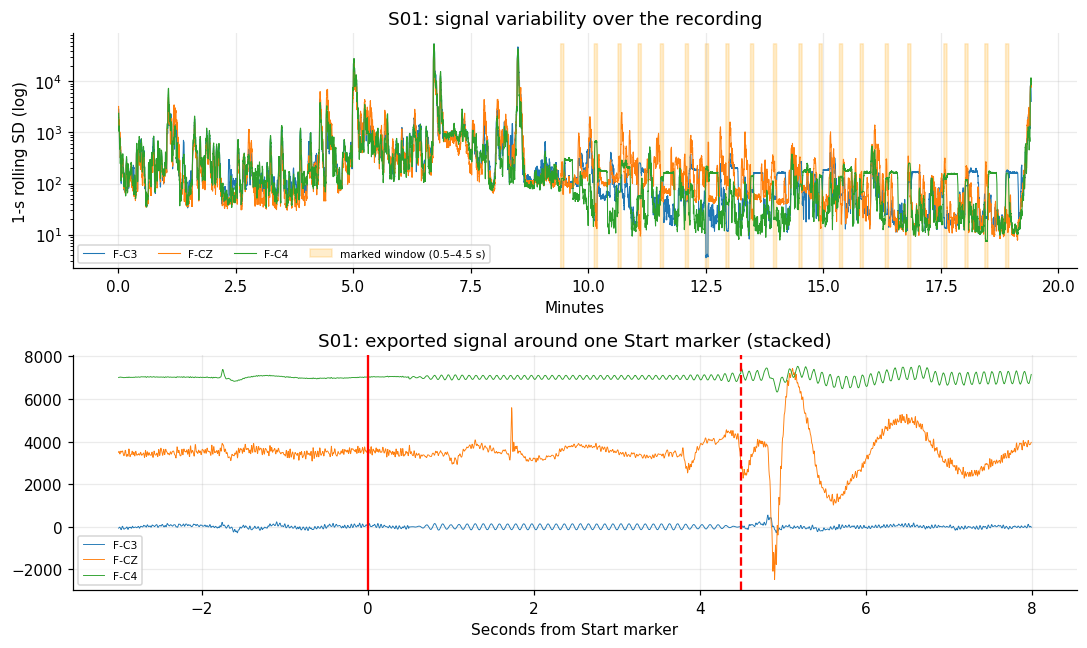

In [47]:
# Cell 10B — compare signal variability and band power inside/outside the marked window

def windows_mask(pid, a=0.5, b=4.5):
    mask = np.zeros(len(H[pid]['raw']), dtype=bool)
    for start in H[pid]['idx']:
        lo = int(start + round(a * FS)); hi = int(start + round(b * FS))
        mask[max(0, lo):min(len(mask), hi)] = True
    return mask

rows = []
for pid in PIDS:
    sig = H[pid]['raw'][:, H[pid]['i3']]
    mask = windows_mask(pid)
    mu = band_filter_cont(sig, 8, 12)
    beta = band_filter_cont(sig, 16, 26)
    for c, channel in enumerate(CH3):
        std_in = sig[mask, c].std()
        std_out = sig[~mask, c].std()
        rows.append(dict(participant=pid, channel=channel,
                         std_in=std_in, std_out=std_out,
                         ratio_std=std_in / (std_out + 1e-12),
                         mu_power_ratio=np.mean(mu[mask, c]**2) / (np.mean(mu[~mask, c]**2) + 1e-12),
                         beta_power_ratio=np.mean(beta[mask, c]**2) / (np.mean(beta[~mask, c]**2) + 1e-12),
                         frac_exact_zero_out=np.mean(sig[~mask, c] == 0)))
D = pd.DataFrame(rows)
D.round(4).to_csv(f'{OUT}/H_inside_vs_outside_window.csv', index=False)
print(D.round(4).to_string(index=False))
print('\nRatios far from 1 warrant inspecting the export and processing history; they are not proof of a particular cause.')

pid = PIDS[0]
sig = H[pid]['raw'][:, H[pid]['i3']]
mask = windows_mask(pid)
t_all = np.arange(len(sig)) / FS / 60
rolling_sd = pd.DataFrame(sig).rolling(FS, center=True).std().to_numpy()
fig, axs = plt.subplots(2, 1, figsize=(10, 6))
for c, channel in enumerate(CH3):
    axs[0].plot(t_all, rolling_sd[:, c], lw=.7, label=channel)
ymax = np.nanmax(rolling_sd)
axs[0].fill_between(t_all, 0, ymax, where=mask, color='orange', alpha=.2, label='marked window (0.5–4.5 s)')
axs[0].set_yscale('log'); axs[0].set_xlabel('Minutes'); axs[0].set_ylabel('1-s rolling SD (log)')
axs[0].set_title(f'{pid}: signal variability over the recording'); axs[0].legend(fontsize=7, ncol=4)
start = int(H[pid]['idx'][min(2, len(H[pid]['idx']) - 1)])
lo = max(0, start - 3 * FS); hi = min(len(sig), start + 8 * FS)
tt = (np.arange(lo, hi) - start) / FS
scale = np.nanstd(sig[lo:hi], axis=0)
for c, channel in enumerate(CH3):
    axs[1].plot(tt, sig[lo:hi, c] + c * 4 * max(scale), lw=.6, label=channel)
axs[1].axvline(0, color='r'); axs[1].axvline(4.5, color='r', ls='--')
axs[1].set_xlabel('Seconds from Start marker'); axs[1].set_title(f'{pid}: exported signal around one Start marker (stacked)')
axs[1].legend(fontsize=7)
save_fig('H_inside_vs_outside_window')


### 10C. Baseline-free C3/C4 power lateralisation

For each epoch, this computes `log10(mu power at C3 / mu power at C4)` and the analogous beta-band measure, then compares right and left trials per participant. Trial-level Mann–Whitney p-values are descriptive because trials from one participant are not independent; the participant-level sign count and signed-rank test are the more relevant group summary. The expected direction depends on the label and channel mapping, so treat it as a check rather than proof of motor-cortex activity.


participant          band  diff_right_minus_left  p_trial_level_descriptive  AUC_right_lower
        S01    mu 8-12 Hz                 1.6296                     0.9812           0.7700
        S01 beta 16-26 Hz                -0.2265                     0.1537           0.3600
        S02    mu 8-12 Hz                 1.2826                     0.9910           0.7175
        S02 beta 16-26 Hz                -0.0641                     0.4196           0.4800
        S03    mu 8-12 Hz                 2.6473                     1.0000           0.8850
        S03 beta 16-26 Hz                 0.3725                     0.9618           0.6625
        S04    mu 8-12 Hz                 1.4384                     0.9852           0.6926
        S04 beta 16-26 Hz                 0.1118                     0.7077           0.5476
        S05    mu 8-12 Hz                 1.2675                     0.9766           0.6825
        S05 beta 16-26 Hz                 0.1945                     0

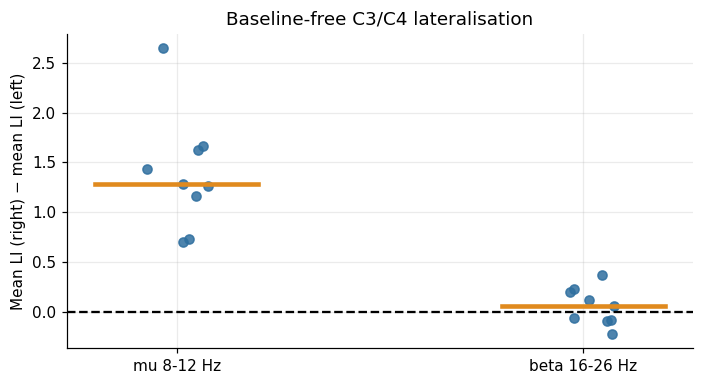

In [48]:
# Cell 10C — baseline-free lateralisation; H y: 0=left, 1=right
from scipy.stats import mannwhitneyu

def epoch_band_power(X, lo, hi):
    freqs, psd = welch(X, fs=FS, nperseg=min(250, X.shape[-1]), axis=-1)
    band = (freqs >= lo) & (freqs < hi)
    return psd[..., band].mean(axis=-1)

rows = []
for pid in PIDS:
    X, y = H[pid]['X'], H[pid]['y']
    for band_name, (lo, hi) in {'mu 8-12 Hz': (8, 12), 'beta 16-26 Hz': (16, 26)}.items():
        power = epoch_band_power(X, lo, hi)
        li = np.log10((power[:, 0] + 1e-30) / (power[:, 2] + 1e-30))  # log(C3/C4)
        left, right = li[y == 0], li[y == 1]
        # right-minus-left difference; expected negative under the assumed mapping.
        diff = right.mean() - left.mean()
        test = mannwhitneyu(right, left, alternative='less', method='asymptotic')
        # AUC for the stated direction (right values lower than left); 0.5 is null.
        auc_right_lower = test.statistic / (len(right) * len(left))
        rows.append(dict(participant=pid, band=band_name, diff_right_minus_left=diff,
                         p_trial_level_descriptive=test.pvalue, AUC_right_lower=auc_right_lower))
L = pd.DataFrame(rows)
L.round(4).to_csv(f'{OUT}/I_lateralisation_baseline_free.csv', index=False)
print(L.round(4).to_string(index=False))
for band_name in L.band.unique():
    vals = L.loc[L.band == band_name, 'diff_right_minus_left'].to_numpy()
    p = wilcoxon(vals, alternative='less', method='exact').pvalue if len(vals) >= 2 and np.any(vals != 0) else 1.0
    print(f'{band_name}: {int((vals < 0).sum())}/{len(vals)} participants negative; median={np.median(vals):.4f}; participant-level one-sided Wilcoxon p={p:.4f}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bands = list(L.band.unique())
for k, band_name in enumerate(bands):
    vals = L.loc[L.band == band_name, 'diff_right_minus_left'].to_numpy()
    jitter = np.random.default_rng(100 + k).uniform(-.08, .08, len(vals))
    ax.scatter(np.full(len(vals), k) + jitter, vals, color='#2f6f9f', alpha=.85)
    ax.plot([k - .2, k + .2], [np.median(vals)] * 2, color='#e08a1e', lw=3)
ax.axhline(0, color='k', ls='--'); ax.set_xticks(range(len(bands))); ax.set_xticklabels(bands)
ax.set_ylabel('Mean LI (right) − mean LI (left)'); ax.set_title('Baseline-free C3/C4 lateralisation')
save_fig('I_lateralisation_baseline_free')


### 10D. Per-class recall and pooled confusion matrix

This summarizes the blocked-CV predictions already produced in Experiment A. `-1` predictions from any fold that could not be fitted are excluded; the cell reports the included trial count. The pooled confusion matrix weights participants by their number of evaluated trials, so use the participant-level table from Experiment A alongside it.


Rows=true (left,right); columns=predicted (left,right)
 [[114  55]
 [ 53 115]]
Evaluated trials: 337 / 337; left recall=0.675; right recall=0.685; pooled BA=0.680


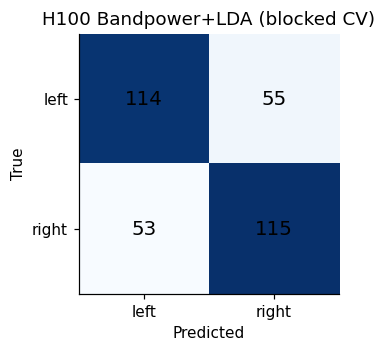

In [49]:
# Cell 10D — pooled confusion matrix for the pre-specified Bandpower+LDA model
from sklearn.metrics import confusion_matrix

yt = np.concatenate([H[pid]['y'] for pid in PIDS])
yp = np.concatenate([PRED[(pid, 'Bandpower+LDA')] for pid in PIDS])
valid = yp >= 0
cm = confusion_matrix(yt[valid], yp[valid], labels=[0, 1])
left_recall = cm[0, 0] / cm[0].sum() if cm[0].sum() else np.nan
right_recall = cm[1, 1] / cm[1].sum() if cm[1].sum() else np.nan
print('Rows=true (left,right); columns=predicted (left,right)\n', cm)
print(f'Evaluated trials: {valid.sum()} / {len(yt)}; left recall={left_recall:.3f}; right recall={right_recall:.3f}; pooled BA={(left_recall + right_recall) / 2:.3f}')
fig, ax = plt.subplots(figsize=(3.8, 3.3))
ax.imshow(cm, cmap='Blues'); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=13)
ax.set_xticks([0, 1]); ax.set_xticklabels(['left', 'right'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['left', 'right'])
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('H100 Bandpower+LDA (blocked CV)')
save_fig('J_confusion_matrix')


### 10E. Verify available EEG columns for channel ablation

Use the printed header to identify EEG columns from the actual export. If there are more than the three analysis columns, set `CH_ALL` in the CONFIG cell to the exact list of EEG columns, including `F-C3`, `F-CZ`, and `F-C4`, then rerun from the loader onward. Experiment F will compare the three-channel subset with the full set. Do not guess channel names or include non-EEG columns.


In [50]:
# Cell 10E — inspect CSV header before configuring CH_ALL
print('First CSV:', files[0])
header = pd.read_csv(files[0], nrows=0, sep=CSV_SEP).columns.tolist()
print('CSV columns:', header)
print('Configured CH3:', CH3)
print('Configured CH_ALL:', CH_ALL if CH_ALL else '(not configured)')


First CSV: /kaggle/input/datasets/vishnupaik/eeg-h100-filtered/h100_filtered/filtered_eeg_01.csv
CSV columns: ['PseudoTimer', 'SampleTimestamp', 'F-FP1', 'F-FP2', 'F-O1', 'F-O2', 'F-C3', 'F-CZ', 'F-FZ', 'F-C4', 'Event', 'EventValue']
Configured CH3: ['F-C3', 'F-CZ', 'F-C4']
Configured CH_ALL: (not configured)


## 11. Save everything


In [51]:
summary = {'smoke_test': SMOKE_TEST, 'versions': VERSIONS, 'participants': PIDS, 'n_trials_h100': int(audit.total.sum()), 'config': dict(K_FOLDS=K_FOLDS, GAP=GAP, N_PERM=N_PERM, SEEDS=SEEDS, EEG_EPOCHS_PRE=EEG_EPOCHS_PRE, EEG_EPOCHS_FT=EEG_EPOCHS_FT, CALIB_SIZES=[str(c) for c in CALIB_SIZES], BAND=BAND, TMIN=TMIN, TMAX=TMAX, CH3=CH3, CH_ALL=CH_ALL, device=DEV)}
json.dump(summary, open(f'{OUT}/run_summary.json', 'w'), indent=1, default=str)
import shutil; zip_path = shutil.make_archive(f'{OUT}/../results_{time.strftime("%Y%m%d_%H%M")}' if not SMOKE_TEST else f'{OUT}/../smoke_results', 'zip', OUT); print('Saved:', zip_path)
print('Kaggle: open the Output panel after saving a notebook version to download the ZIP.')

Saved: /kaggle/working/results_20261101_1411.zip
Kaggle: open the Output panel after saving a notebook version to download the ZIP.
